<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>



# **Final Project: Boston Housing**


##### Estimated time needed: **60** minutes


#### Import the required libraries we need for the lab.


In [2]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [3]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

<ipython-input-3-b3fdaf15785b>:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


#### Read the dataset in the csv file from the URL


In [4]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())


In [5]:
boston_df=pd.read_csv(boston_url)
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [6]:
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

In [7]:
boston_df.isnull().sum()

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

In [8]:
boston_df.duplicated().sum()

0

In [9]:
boston_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


### Descriptive statistics

In [10]:
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


1. The dataset has 506 records with no missing values.

2. Median home values average about 22,500, ranging from 5,000 to a capped maximum of $50,000.

3. Crime rates are highly uneven, with most towns near zero and a few extreme outliers.

4.  Only about 35 homes border the Charles River, and most areas have a large share of homes built before 1940.

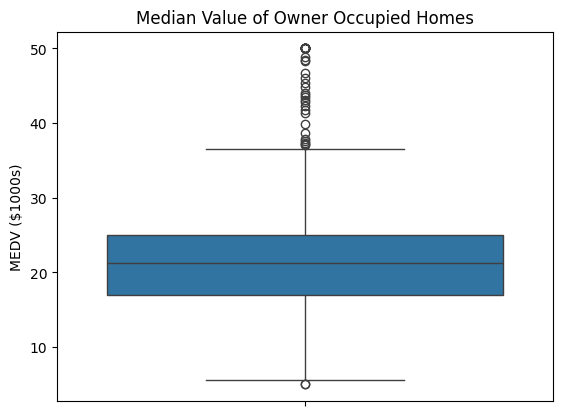

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(y=boston_df["MEDV"])
plt.title("Median Value of Homes")
plt.ylabel("MEDV ($1000)")
plt.show()

Most areas have median home values between 17,000 and 25,000, with a median of about 21,200. A group of high value areas sits well above the rest, from about $37,000 up to the 50,000 cap, which pulls the average slightly above the median. Only one area falls unusually low, at 5,000.

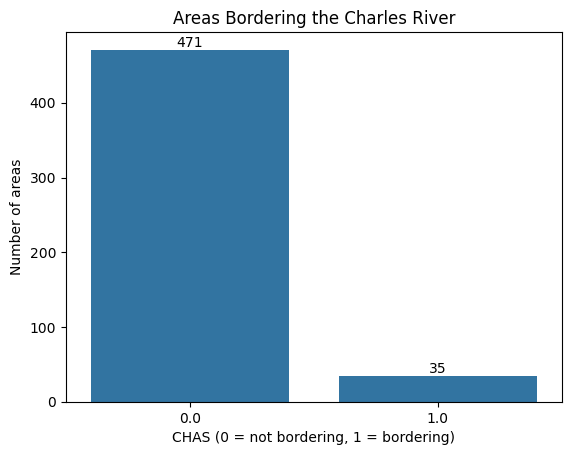

In [13]:
ax = sns.countplot(x="CHAS", data=boston_df)
ax.bar_label(ax.containers[0])
plt.title("Areas Bordering the Charles River")
plt.xlabel("CHAS (0 = not bordering, 1 = bordering)")
plt.ylabel("Number of areas")
plt.show()

Only about 35 of the 506 areas border the Charles River, while about 471 do not.

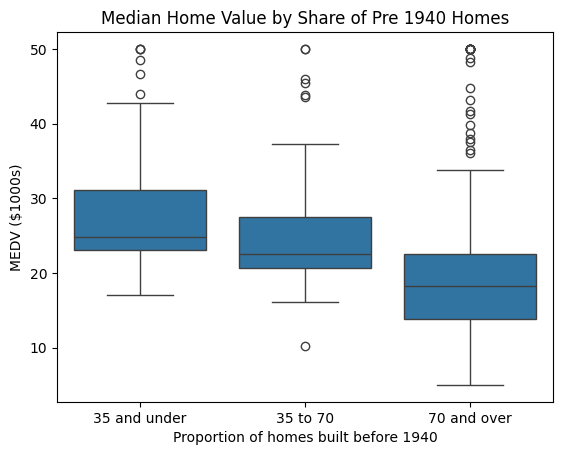

In [14]:
boston_df["AGE_GROUP"] = pd.cut(
    boston_df["AGE"],
    bins=[0, 35, 70, 100],
    labels=["35 and under", "35 to 70", "70 and over"]
)

sns.boxplot(x="AGE_GROUP", y="MEDV", data=boston_df)
plt.title("Median Home Value by Share of Pre 1940 Homes")
plt.xlabel("Proportion of homes built before 1940")
plt.ylabel("MEDV ($1000s)")
plt.show()

Areas with a higher share of homes built before 1940 tend to have lower median values, falling from about 24,800 in the newest group to about 18,200 in the oldest. The oldest group also varies the most, containing both the lowest valued areas and several at the 50,000 cap.

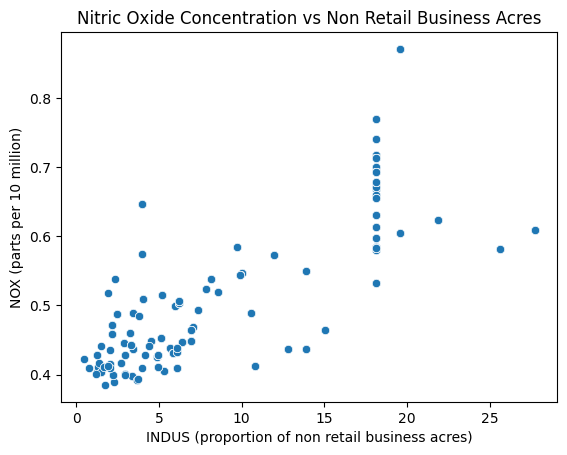

In [16]:
sns.scatterplot(x="INDUS", y="NOX", data=boston_df)
plt.title("Nitric Oxide Concentration vs Non Retail Business Acres")
plt.xlabel("INDUS (proportion of non retail business acres)")
plt.ylabel("NOX (parts per 10 million)")
plt.show()

Areas with more non retail business land generally have higher nitric oxide concentrations. Areas with little industrial land mostly fall between 0.38 and 0.50 parts per 10 million, while the most industrial areas reach as high as 0.87. A large group of areas shares the same industrial share of about 18 yet varies widely in pollution, suggesting other factors such as traffic also play a part. 

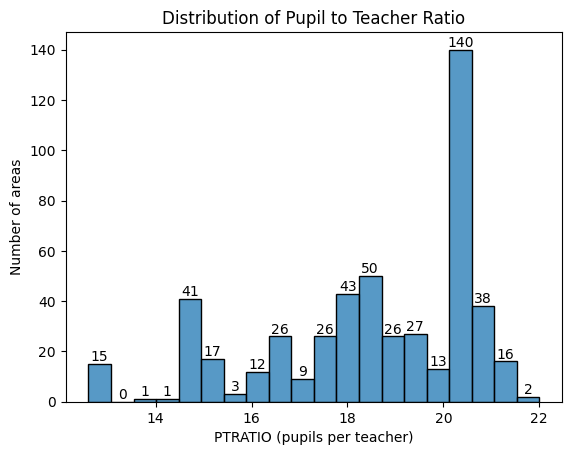

In [19]:
ax=sns.histplot(boston_df["PTRATIO"], bins=20)
ax.bar_label(ax.containers[0])
plt.title("Distribution of Pupil to Teacher Ratio")
plt.xlabel("PTRATIO (pupils per teacher)")
plt.ylabel("Number of areas")
plt.show()

Most areas have between 17 and 21 pupils per teacher, with about 140 areas sharing a ratio of roughly 20, likely because they fall in the same school district. A small group of about 15 areas has notably smaller classes, near 12.6 pupils per teacher. The overall average is about 18.5.

### Task 3: Statistical tests

In [21]:
#levene's test
from scipy import stats
river = boston_df[boston_df["CHAS"] == 1]["MEDV"]
no_river = boston_df[boston_df["CHAS"] == 0]["MEDV"]

stats.levene(river, no_river, center="mean")

LeveneResult(statistic=8.75190489604598, pvalue=0.003238119367639829)

Levene’s test gave a p value of 0.003, below the 0.05 significance level, so we reject the null hypothesis that the two groups have equal variances. Home values for areas bordering the Charles River vary differently from those that do not, so we use a t-test that does not assume equal variances.

In [22]:
#T-test
stats.ttest_ind(river, no_river, equal_var=False)

TtestResult(statistic=3.113291312794837, pvalue=0.003567170098137517, df=36.876408797611994)

In [23]:
boston_df.groupby("CHAS")["MEDV"].mean()

CHAS
0.0    22.093843
1.0    28.440000
Name: MEDV, dtype: float64

Using a significance level of 0.05, the t-test gave a p value of 0.004, so we reject the null hypothesis. Areas bordering the Charles River have significantly higher median home values, averaging about 28,400 compared with about 22,100 for other areas.

In [24]:
#ANOVA
group1 = boston_df[boston_df["AGE_GROUP"] == "35 and under"]["MEDV"]
group2 = boston_df[boston_df["AGE_GROUP"] == "35 to 70"]["MEDV"]
group3 = boston_df[boston_df["AGE_GROUP"] == "70 and over"]["MEDV"]

stats.f_oneway(group1, group2, group3)

F_onewayResult(statistic=36.40764999196599, pvalue=1.7105011022702984e-15)

Using a significance level of 0.05, a one way ANOVA gave an F statistic of 36.4 and a p value far below 0.001, so we reject the null hypothesis. Median home values differ significantly across the three age groups, with areas that have the highest share of pre 1940 homes showing the lowest values.

In [25]:
#Pearson
stats.pearsonr(boston_df["NOX"], boston_df["INDUS"])

PearsonRResult(statistic=0.7636514469209192, pvalue=7.913361061210442e-98)

Using a significance level of 0.05, a Pearson correlation test gave r = 0.76 with a p value far below 0.001, so we reject the null hypothesis. There is a strong positive relationship between non retail business acres and nitric oxide concentration.

In [26]:
#regression
X = sm.add_constant(boston_df["DIS"])
y = boston_df["MEDV"]

model = sm.OLS(y, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        22:53:05   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.000      16.784      19.996
DIS            1.0916      0.188      5.795      0.000       0.722       1.462
==============================================================================
Omnibus:                      139.779   Durbin-Watson:                   0.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              305.104
Skew:                           1.466   Prob(JB):                     5.59e-67
Kurtosis:                       5.424   Cond. No.                         9.32
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

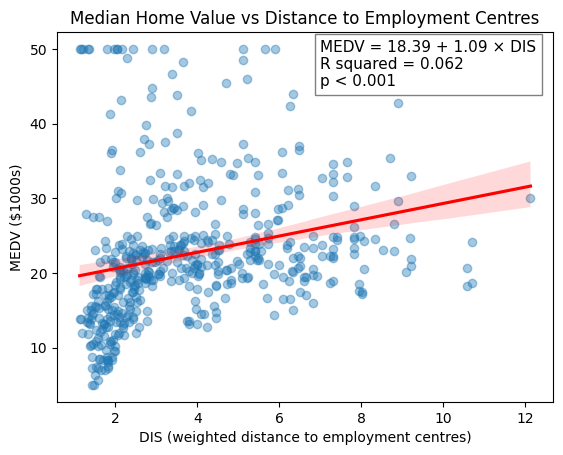

In [27]:
ax = sns.regplot(
    x="DIS", y="MEDV", data=boston_df,
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

ax.text(
    7, 45,
    "MEDV = 18.39 + 1.09 × DIS\nR squared = 0.062\np < 0.001",
    fontsize=11,
    bbox=dict(facecolor="white", edgecolor="gray")
)

plt.title("Median Home Value vs Distance to Employment Centres")
plt.xlabel("DIS (weighted distance to employment centres)")
plt.ylabel("MEDV ($1000s)")
plt.show()

Using a significance level of 0.05, a simple linear regression shows that distance to the Boston employment centres has a significant positive effect on median home value (p < 0.001). Each additional unit of weighted distance is associated with an increase of about $1,090. However, distance explains only about 6 parts in 100 of the variation in home values (R squared = 0.062), so other factors such as room count and neighbourhood income matter far more.